# Predicting Energy Use and Load State in a Smart Steel Plant

One year of 15-minute electricity readings from a steel manufacturer, analysed with
unsupervised learning, regression and classification.

| Question | Approach |
|---|---|
| How much electricity will the plant use in a 15-minute interval? | Regression on `Usage_kWh` |
| Which operating state is the plant in: light, medium or maximum load? | Classification on `Load_Type` |
| Does the data contain natural operating regimes that we can find without labels? | PCA and K-Means clustering |

**Design choices that apply throughout**
- `CO2(tCO2)` is never used as a predictor. It is calculated directly from electricity use, so it would leak the regression target.
- All models use the same reduced set of six non-redundant features (see Section 3.3).
- Hyperparameters are tuned by cross-validation on the training data only; each test set is used once.
- Class weights offset the class imbalance in every classifier that supports them.
- PCA and K-Means are exploratory and are fitted on the full dataset without using any labels.

### Data and attribution

- **Dataset:** Sathishkumar V E, Shin C, Cho Y (2021). *Steel Industry Energy Consumption* [Dataset].
  UCI Machine Learning Repository. https://doi.org/10.24432/C52G8C. Licensed under
  [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
- **Original study:** Sathishkumar V E, Shin C, Cho Y (2021). Efficient energy consumption prediction
  model for a data analytic-enabled industry building in a smart city. *Building Research & Information*,
  49(1), 127–143. https://doi.org/10.1080/09613218.2020.1809983

The data covers 35,040 readings taken every 15 minutes throughout 2018 at DAEWOO Steel Co. Ltd in
Gwangyang, South Korea. Smart meters recorded the readings and the KEPCO cloud platform stored them.

## Contents

1. [Setup](#setup)
2. [Load and prepare the data](#load)
3. [Exploratory data analysis](#eda)
4. [Unsupervised learning: PCA and K-Means](#unsupervised)
5. [Regression: predicting `Usage_kWh`](#regression)
6. [Classification: predicting `Load_Type`](#classification)
7. [Ablation: how much of `Load_Type` is just the schedule?](#ablation)

<a id="setup"></a>
## 1. Setup

All imports and settings live in the next two cells, so the analysis below contains no hidden
constants.

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import f_oneway
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
    silhouette_score,
)
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

# Keep the output readable; the code has been checked for warnings that matter.
warnings.filterwarnings("ignore")
# Parallel grid-search workers are separate processes that don't inherit the filter above;
# they read this environment variable instead.
os.environ["PYTHONWARNINGS"] = "ignore"

In [2]:
# ---- Paths and reproducibility --------------------------------------------------------------
DATA_PATH = Path("../data/raw/Steel_industry_data.csv")
SEED = 10                 # used for every split, CV fold, model and sample
REGRESSION_TREE_SEED = 7  # the published regression results used 7 for the tree models; kept so they reproduce
TEST_SIZE = 0.2
CV_FOLDS = 5

# ---- Targets --------------------------------------------------------------------------------
REG_TARGET = "Usage_kWh"
CLF_TARGET = "Load_Type"
LOAD_ORDER = ["Light_Load", "Medium_Load", "Maximum_Load"]

# ---- Features -------------------------------------------------------------------------------
# Short display names for the raw and engineered columns.
SHORT_NAMES = {
    "Lagging_Current_Reactive.Power_kVarh": "Lag.React.Power",
    "Leading_Current_Reactive_Power_kVarh": "Lead.React.Power",
    "CO2(tCO2)": "CO2",
    "Lagging_Current_Power_Factor": "Lag.PF",
    "Leading_Current_Power_Factor": "Lead.PF",
    "NSM": "NSM",
    "Hour": "Hour",
    "Month": "Month",
    "Is_Weekend": "Is_Weekend",
}

# Every candidate predictor except CO2 (a leakage variable); used for EDA.
EDA_FEATURES = [
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor",
    "NSM",
    "Hour",
    "Month",
    "Is_Weekend",
]

# The six features used by every model. NSM duplicates Hour, and leading reactive power
# duplicates leading power factor, so both are dropped (Section 3.3 shows the correlations).
MODEL_FEATURES = [
    "Lagging_Current_Reactive.Power_kVarh",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor",
    "Hour",
    "Month",
    "Is_Weekend",
]

# Electrical measurements only: used in the ablation (Section 7).
ELECTRICAL_FEATURES = MODEL_FEATURES[:3]

# ---- Plot style -----------------------------------------------------------------------------
PALETTE = {"Light_Load": "#2196F3", "Medium_Load": "#FF9800", "Maximum_Load": "#F44336"}

plt.rcParams.update({
    "figure.dpi": 140,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "lines.linewidth": 2,
    "legend.frameon": False,
})


def short(columns):
    """Display names for a list of column names."""
    return [SHORT_NAMES.get(c, c) for c in columns]


assert not {"CO2(tCO2)", REG_TARGET} & set(MODEL_FEATURES), "leakage column in the model features"
print("Setup complete:", len(MODEL_FEATURES), "model features,", f"seed {SEED}")

Setup complete: 6 model features, seed 10


<a id="load"></a>
## 2. Load and prepare the data

Each row is one 15-minute interval. Three time features are derived from the timestamp, because
the plant's energy use follows its working schedule:
- `Hour` (0–23) for the time of day
- `Month` (1–12) for the season
- `Is_Weekend` (0 or 1), from the dataset's `WeekStatus` column

In [3]:
def load_data(path):
    """Read the raw CSV and parse the timestamp column (dates are day-first, e.g. 31/12/2018)."""
    df = pd.read_csv(path)
    return df.assign(date=pd.to_datetime(df["date"], dayfirst=True))


def add_time_features(df):
    """Add Hour, Month and Is_Weekend, derived from the timestamp and WeekStatus."""
    return df.assign(
        Hour=df["date"].dt.hour,
        Month=df["date"].dt.month,
        Is_Weekend=(df["WeekStatus"] == "Weekend").astype(int),
    )


df = add_time_features(load_data(DATA_PATH))
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

35,040 rows x 14 columns


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type,Hour,Month,Is_Weekend
0,2018-01-01 00:15:00,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load,0,1,0
1,2018-01-01 00:30:00,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load,0,1,0
2,2018-01-01 00:45:00,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load,0,1,0
3,2018-01-01 01:00:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load,1,1,0
4,2018-01-01 01:15:00,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load,1,1,0


### 2.1 Data quality checks

Before any analysis, confirm that every timestamp parsed, nothing is missing or duplicated, and
both targets look as expected.

In [4]:
quality = pd.Series({
    "rows": len(df),
    "missing values": int(df.isna().sum().sum()),
    "duplicate rows": int(df.duplicated().sum()),
    "unparsed timestamps": int(df["date"].isna().sum()),
    "first timestamp": df["date"].min(),
    "last timestamp": df["date"].max(),
})
print(quality.to_string())

load_counts = df[CLF_TARGET].value_counts().reindex(LOAD_ORDER)
print("\nLoad_Type counts:")
print(pd.DataFrame({"count": load_counts, "share": (load_counts / len(df)).round(3)}).to_string())

df.describe().T.round(3)

rows                                 35040
missing values                           0
duplicate rows                           0
unparsed timestamps                      0
first timestamp        2018-01-01 00:00:00
last timestamp         2018-12-31 23:45:00

Load_Type counts:
              count  share
Load_Type                 
Light_Load    18072  0.516
Medium_Load    9696  0.277
Maximum_Load   7272  0.208


,count,mean,min,25%,50%,75%,max,std
date,35040,2018-07-02 11:52:30,2018-01-01 00:00:00,2018-04-02 05:56:15,2018-07-02 11:52:30,2018-10-01 17:48:45,2018-12-31 23:45:00,NaN
Usage_kWh,35040.0,27.386892,0.0,3.2,4.57,51.2375,157.18,33.44438
Lagging_Current_Reactive.Power_kVarh,35040.0,13.035384,0.0,2.3,5.0,22.64,96.91,16.306
Leading_Current_Reactive_Power_kVarh,35040.0,3.870949,0.0,0.0,0.0,2.09,27.76,7.424463
CO2(tCO2),35040.0,0.011524,0.0,0.0,0.0,0.02,0.07,0.016151
Lagging_Current_Power_Factor,35040.0,80.578056,0.0,63.32,87.96,99.0225,100.0,18.921322
Leading_Current_Power_Factor,35040.0,84.36787,0.0,99.7,100.0,100.0,100.0,30.456535
NSM,35040.0,42750.0,0.0,21375.0,42750.0,64125.0,85500.0,24940.534317
Hour,35040.0,11.5,0.0,5.75,11.5,17.25,23.0,6.922285
Month,35040.0,6.526027,1.0,4.0,7.0,10.0,12.0,3.447901


<a id="eda"></a>
## 3. Exploratory data analysis

The EDA answers four questions before any modelling:
- What do the two targets look like?
- Which predictors are redundant or leak the target?
- Is `Load_Type` just a binned version of `Usage_kWh`?
- How strongly does the plant's schedule shape its energy use?

### 3.1 Target distributions

- **`Usage_kWh` is strongly right-skewed** (skewness ≈ 1.20). Most intervals are low-consumption
  or idle, with a long tail of high-consumption production periods. A `log(1 + x)` transform brings
  the skewness down to ≈ 0.49. The models still use the original kWh scale, so errors stay in real
  units and are comparable with the original study.
- **`Load_Type` is moderately imbalanced:** Light 51.6%, Medium 27.7%, Maximum 20.8%. Accuracy
  would reward a model for favouring `Light_Load`, so classifiers are compared on **macro-F1**,
  which weights the three classes equally.

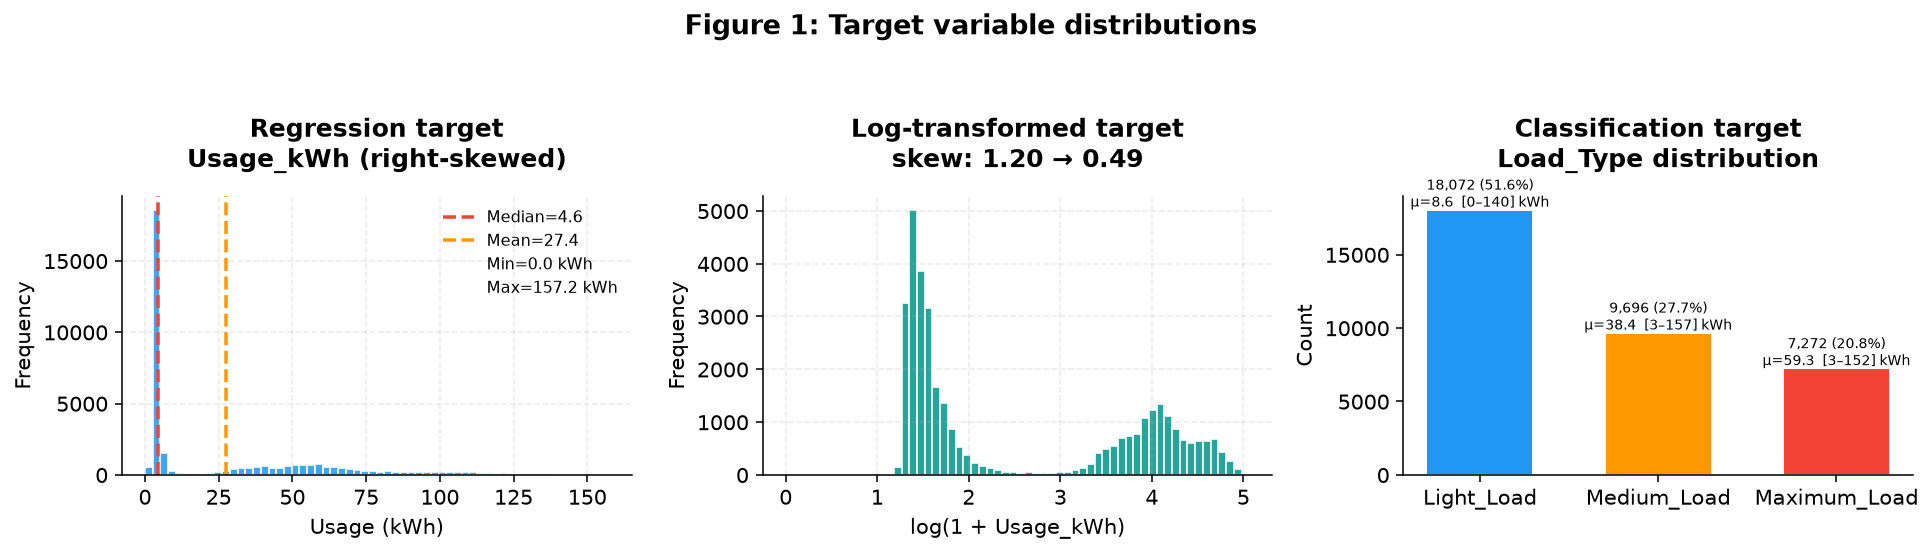

In [5]:
def plot_target_distributions(df):
    """Usage_kWh on the raw and log scales, and the Load_Type class counts."""
    usage = df[REG_TARGET]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    fig.suptitle("Figure 1: Target variable distributions", fontweight="bold", fontsize=14)

    axes[0].hist(usage, bins=60, color="#2196F3", edgecolor="white", alpha=0.85)
    axes[0].axvline(usage.median(), color="#F44336", ls="--", lw=1.8, label=f"Median={usage.median():.1f}")
    axes[0].axvline(usage.mean(), color="#FF9800", ls="--", lw=1.8, label=f"Mean={usage.mean():.1f}")
    axes[0].plot([], [], " ", label=f"Min={usage.min():.1f} kWh")
    axes[0].plot([], [], " ", label=f"Max={usage.max():.1f} kWh")
    axes[0].set(xlabel="Usage (kWh)", ylabel="Frequency")
    axes[0].set_title("Regression target\nUsage_kWh (right-skewed)", pad=15)
    axes[0].legend(fontsize=8)

    log_usage = np.log1p(usage)
    axes[1].hist(log_usage, bins=60, color="#009688", edgecolor="white", alpha=0.85)
    axes[1].set(xlabel="log(1 + Usage_kWh)", ylabel="Frequency")
    axes[1].set_title(f"Log-transformed target\nskew: {usage.skew():.2f} → {log_usage.skew():.2f}", pad=15)

    counts = df[CLF_TARGET].value_counts()
    bars = axes[2].bar(counts.index, counts.values, color=[PALETTE[k] for k in counts.index],
                       edgecolor="white", width=0.6)
    for bar, (load_type, count) in zip(bars, counts.items()):
        group = df.loc[df[CLF_TARGET] == load_type, REG_TARGET]
        axes[2].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 200,
                     f"{count:,} ({count / len(df):.1%})\n"
                     f"μ={group.mean():.1f}  [{group.min():.0f}–{group.max():.0f}] kWh",
                     ha="center", fontsize=7)
    axes[2].set_title("Classification target\nLoad_Type distribution", pad=15)
    axes[2].set_ylabel("Count")
    axes[2].grid(False)

    fig.tight_layout(rect=[0, 0, 1, 0.93])
    return fig


plot_target_distributions(df)
plt.show()

### 3.2 Feature distributions

- **Lagging reactive power** is strongly right-skewed: reactive demand is usually low, with
  occasional periods of much higher load.
- **Leading reactive power** sits near zero most of the time. Leading compensation only matters
  during particular operating periods.
- **Both power factors** look regime-like:
  - Lagging PF has a large mass at high values and a broad spread below.
  - Leading PF is mostly at 100 with a smaller low-value group.

  Both point to distinct operating conditions.
- **NSM and Hour** are uniform by construction, so every time of day is equally represented.
- **Month** is roughly uniform too.
- **Is_Weekend** leans towards weekdays (five of seven days).
- **CO₂** is left out here and in every model. Section 3.3 shows why.

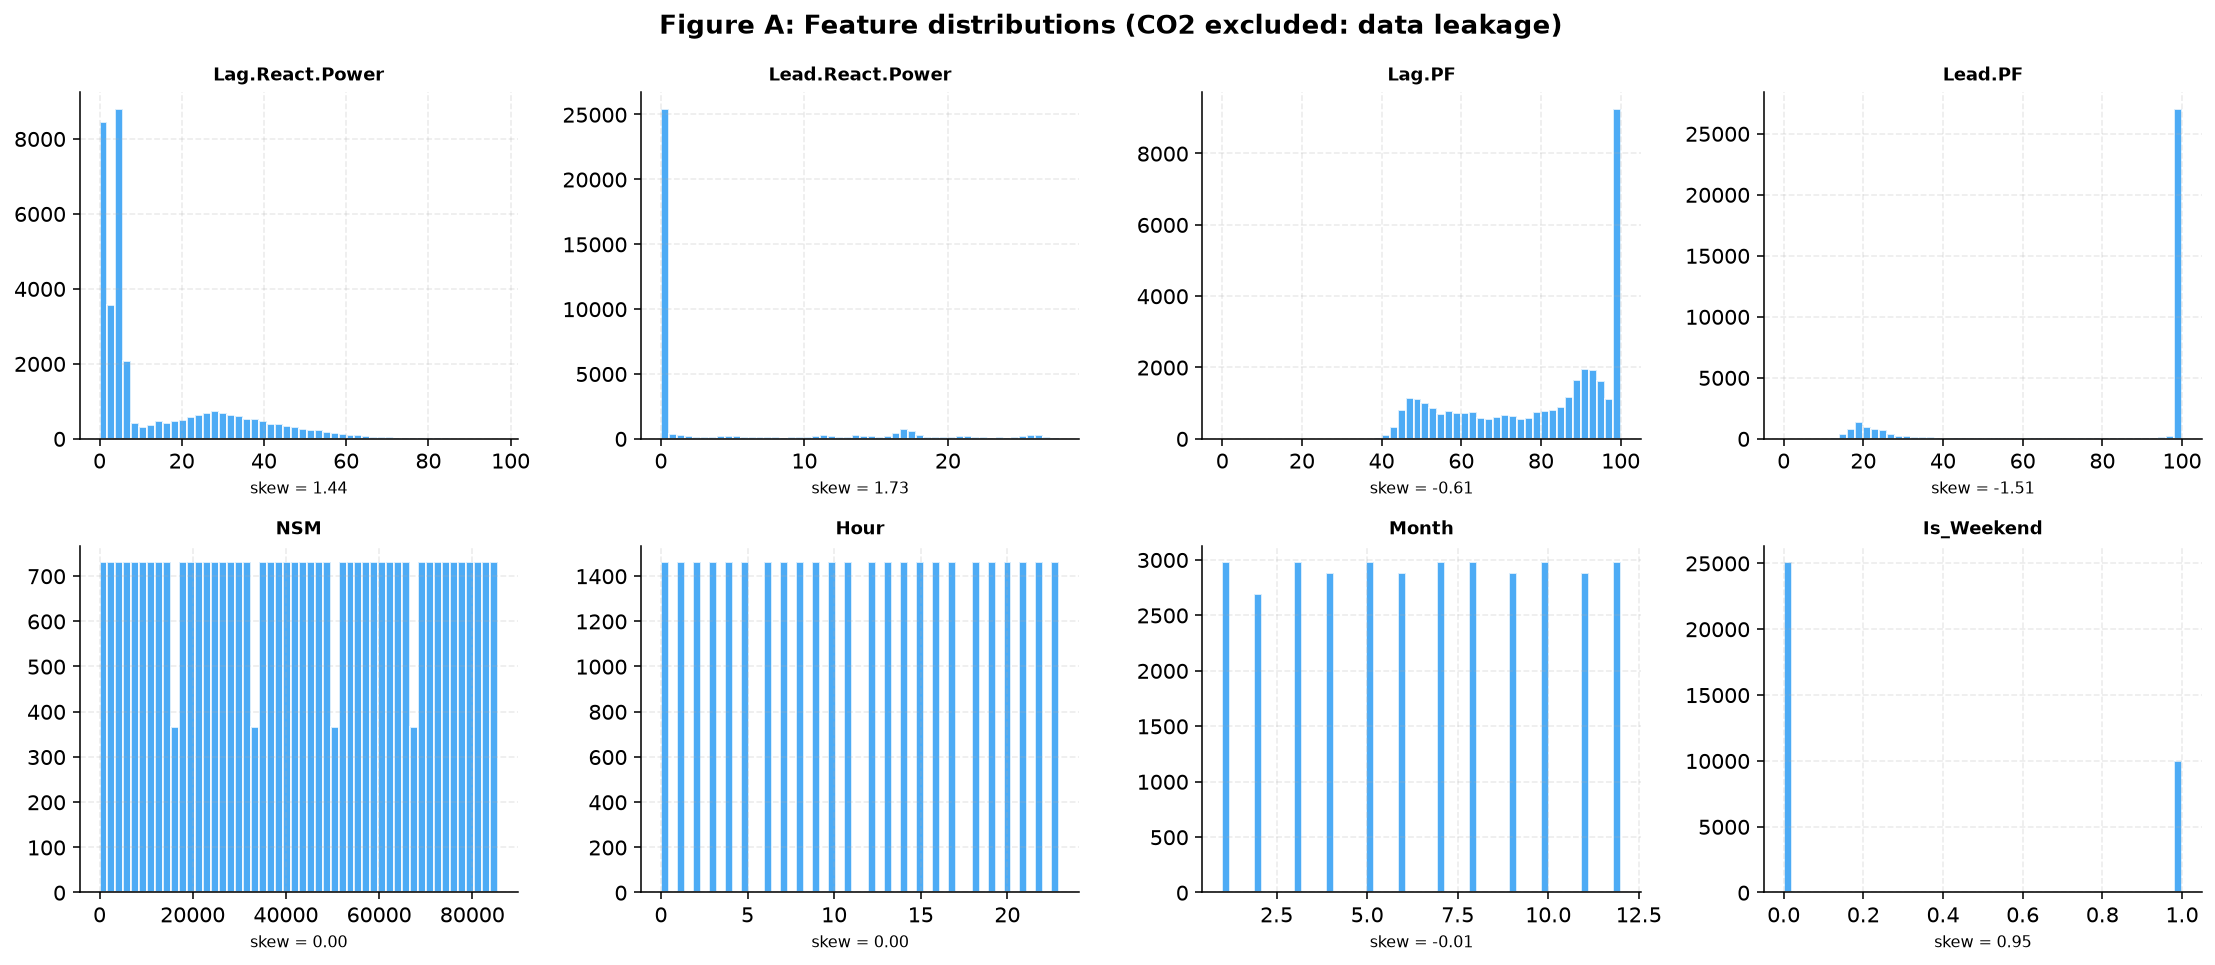

In [6]:
def plot_feature_distributions(df, features):
    """One histogram per feature, with its skewness."""
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    fig.suptitle("Figure A: Feature distributions (CO2 excluded: data leakage)", fontweight="bold")
    for ax, column in zip(axes.flatten(), features):
        ax.hist(df[column], bins=50, color="#2196F3", edgecolor="white", alpha=0.8)
        ax.set_title(SHORT_NAMES[column], fontsize=9)
        ax.set_xlabel(f"skew = {df[column].skew():.2f}", fontsize=8)
    fig.tight_layout()
    return fig


plot_feature_distributions(df, EDA_FEATURES)
plt.show()

### 3.3 Correlations, leakage and redundancy

The correlation matrix drives three feature decisions:

1. **`CO2(tCO2)` leaks the target (r = 0.99 with `Usage_kWh`).** The dataset calculates CO₂ from
   electricity use with a fixed emissions factor, so it carries no independent information.
   Using it as a predictor would hand the model the answer. **It is excluded from every model.**
2. **`NSM` duplicates `Hour` (r = 1.00).** Both encode the time of day. `Hour` is kept.
3. **Leading reactive power duplicates leading power factor (r = −0.94).** Both reflect capacitor
   compensation. Leading power factor is kept.

That leaves the six modelling features defined in the setup cell. `Lagging_Current_Reactive.Power_kVarh`
is the strongest legitimate predictor of `Usage_kWh` (r = 0.90).

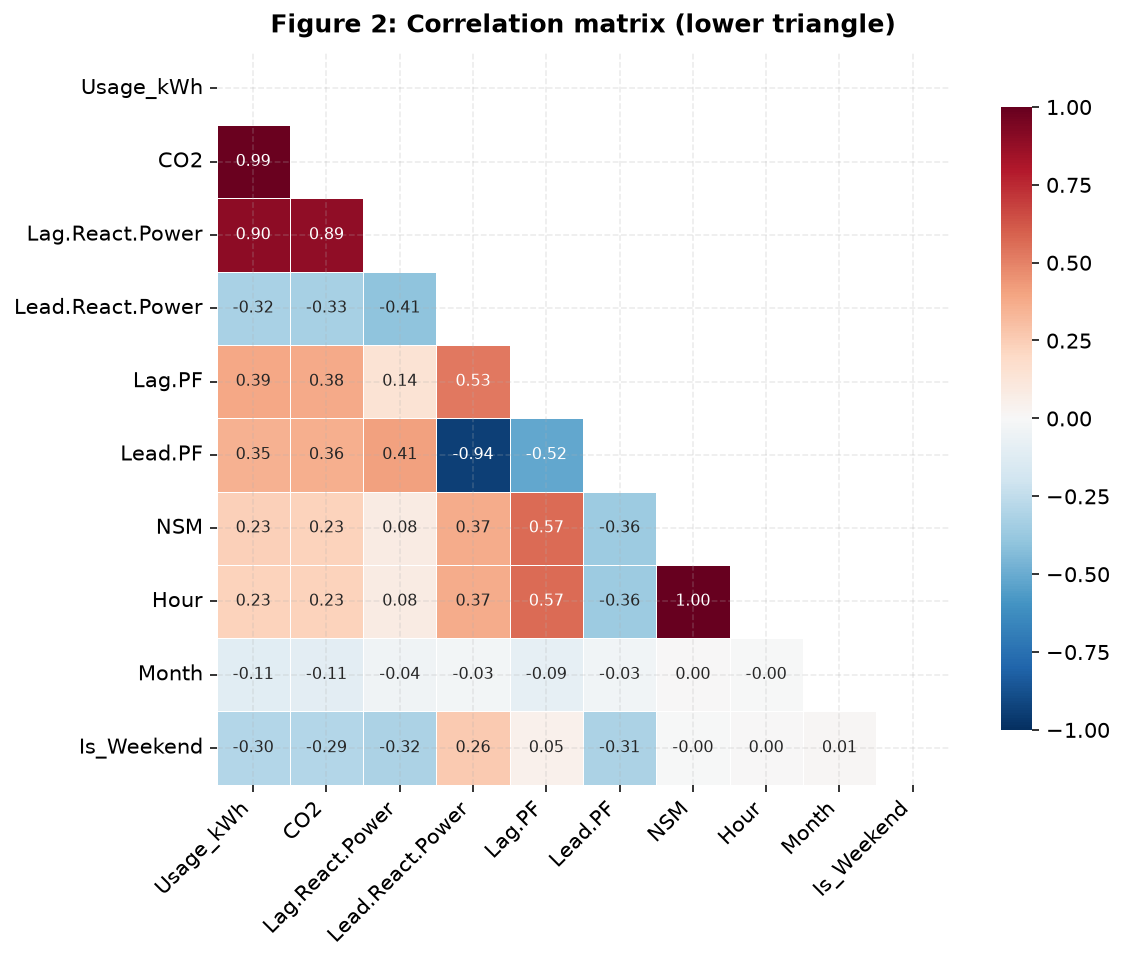

CO2 vs Usage_kWh               r = +0.9882
NSM vs Hour                    r = +0.9992
Lead.React.Power vs Lead.PF    r = -0.9440
Lag.React.Power vs Usage_kWh   r = +0.8961


In [7]:
def plot_correlations(df, columns):
    """Lower-triangle correlation heatmap."""
    corr = df[columns].corr()
    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt=".2f",
                cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
                annot_kws={"size": 8}, xticklabels=short(columns), yticklabels=short(columns),
                cbar_kws={"shrink": 0.85}, ax=ax)
    ax.set_title("Figure 2: Correlation matrix (lower triangle)", fontweight="bold", pad=10)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout()
    return fig


# CO2 is included here on purpose, to make the leakage visible.
plot_correlations(df, [REG_TARGET, "CO2(tCO2)"] + EDA_FEATURES)
plt.show()

pairs = {
    "CO2 vs Usage_kWh": ("CO2(tCO2)", REG_TARGET),
    "NSM vs Hour": ("NSM", "Hour"),
    "Lead.React.Power vs Lead.PF": ("Leading_Current_Reactive_Power_kVarh", "Leading_Current_Power_Factor"),
    "Lag.React.Power vs Usage_kWh": ("Lagging_Current_Reactive.Power_kVarh", REG_TARGET),
}
for label, (a, b) in pairs.items():
    print(f"{label:<30} r = {df[a].corr(df[b]):+.4f}")

### 3.4 Is `Load_Type` just binned `Usage_kWh`?

If each load type were simply a band of kWh values, classification would be trivial and the two
tasks would be one. The question isn't whether the two targets are related: they clearly are.
It's whether `Load_Type` is a *deterministic* banding of `Usage_kWh`. Three tests check this:

1. **Visual:** do the kWh ranges of the three classes overlap? (box plot and density plot)
2. **Statistical:** do the class means differ? (one-way ANOVA)
3. **Predictive:** how well does a logistic regression recover `Load_Type` from `Usage_kWh` alone?

**Result: no, it is not a binning.**
- The kWh ranges overlap almost completely. 99.2% of Light_Load intervals fall inside the
  Medium_Load range.
- The ANOVA confirms the class means differ: the targets are associated, not identical.
- Using kWh alone, a logistic regression reaches only about 63% accuracy. Always guessing
  `Light_Load` already scores 52%.

`Load_Type` is an operational label, the plant's scheduled production mode, not a transformation
of consumption.

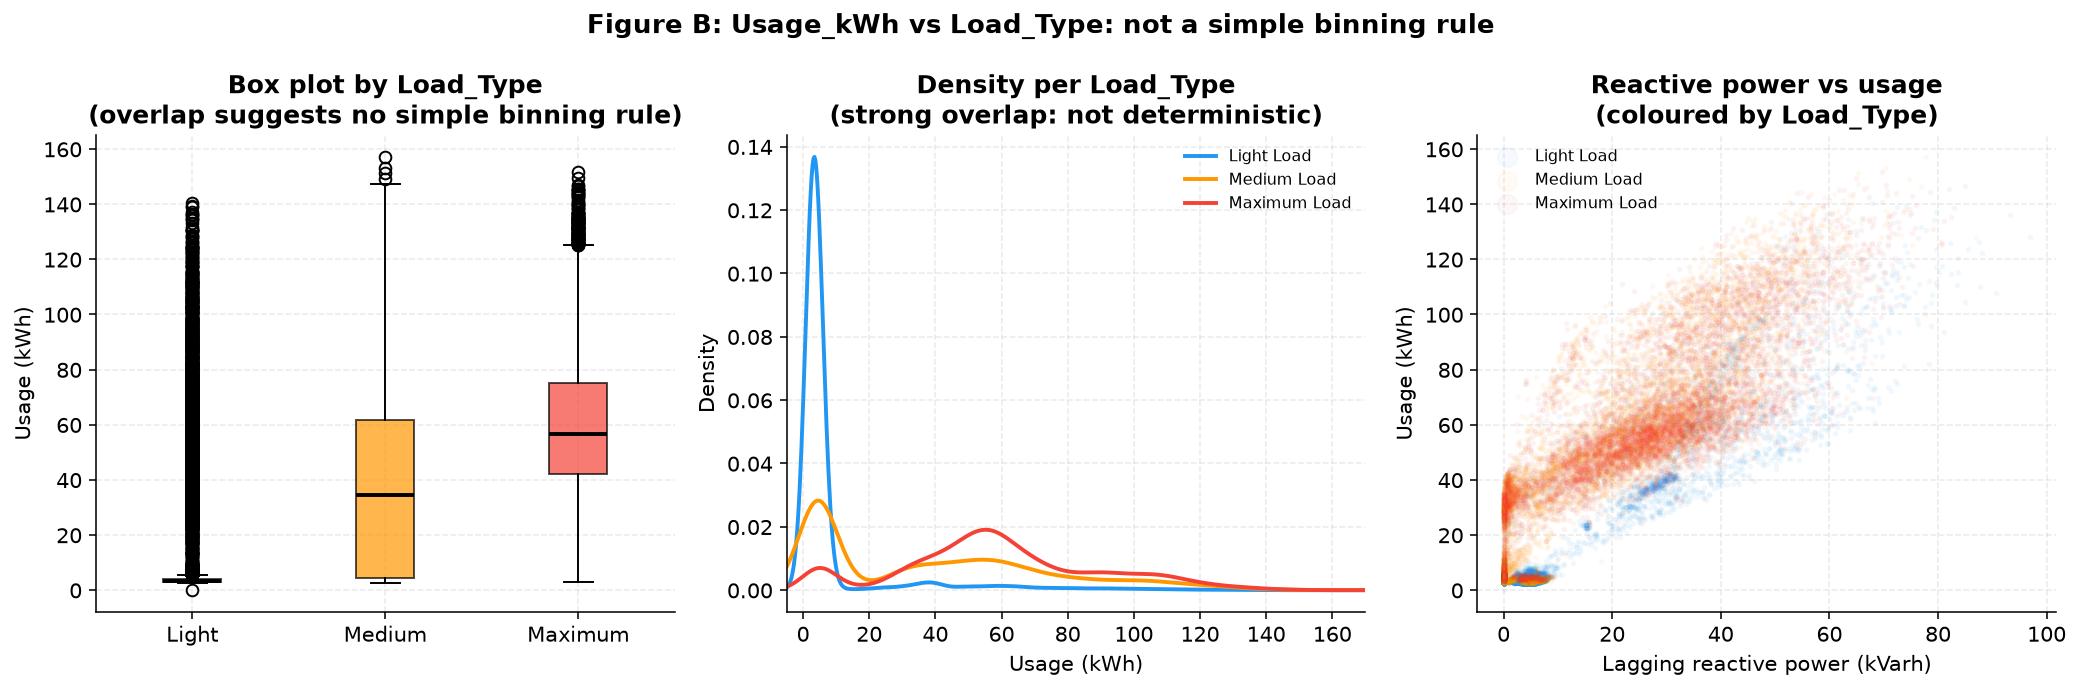

               min     max   mean
Load_Type                        
Light_Load    0.00  140.29   8.63
Medium_Load   2.52  157.18  38.45
Maximum_Load  2.92  151.67  59.27

99.2% of Light_Load intervals fall inside the Medium_Load kWh range


In [8]:
def plot_usage_by_load_type(df):
    """Box plot, density plot and reactive-power scatter of Usage_kWh by load type."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle("Figure B: Usage_kWh vs Load_Type: not a simple binning rule", fontweight="bold")

    groups = [df.loc[df[CLF_TARGET] == lt, REG_TARGET].values for lt in LOAD_ORDER]
    box = axes[0].boxplot(groups, tick_labels=["Light", "Medium", "Maximum"], patch_artist=True,
                          medianprops=dict(color="black", lw=2))
    for patch, load_type in zip(box["boxes"], LOAD_ORDER):
        patch.set_facecolor(PALETTE[load_type])
        patch.set_alpha(0.7)
    axes[0].set_ylabel("Usage (kWh)")
    axes[0].set_title("Box plot by Load_Type\n(overlap suggests no simple binning rule)")

    for load_type, colour in PALETTE.items():
        df.loc[df[CLF_TARGET] == load_type, REG_TARGET].plot.kde(
            ax=axes[1], color=colour, lw=2, label=load_type.replace("_", " "))
    axes[1].set(xlabel="Usage (kWh)", ylabel="Density", xlim=(-5, 170))
    axes[1].set_title("Density per Load_Type\n(strong overlap: not deterministic)")
    axes[1].legend(fontsize=8)

    for load_type, colour in PALETTE.items():
        subset = df[df[CLF_TARGET] == load_type]
        axes[2].scatter(subset["Lagging_Current_Reactive.Power_kVarh"], subset[REG_TARGET],
                        c=colour, alpha=0.04, s=4, label=load_type.replace("_", " "))
    axes[2].set(xlabel="Lagging reactive power (kVarh)", ylabel="Usage (kWh)")
    axes[2].set_title("Reactive power vs usage\n(coloured by Load_Type)")
    axes[2].legend(fontsize=8, markerscale=5)

    fig.tight_layout()
    return fig


plot_usage_by_load_type(df)
plt.show()

# Test 1 in numbers: the kWh range of each class, and how much Light overlaps Medium.
ranges = df.groupby(CLF_TARGET)[REG_TARGET].agg(["min", "max", "mean"]).reindex(LOAD_ORDER)
print(ranges.round(2).to_string())
light = df.loc[df[CLF_TARGET] == "Light_Load", REG_TARGET]
overlap = (light > ranges.loc["Medium_Load", "min"]).mean()
print(f"\n{overlap:.1%} of Light_Load intervals fall inside the Medium_Load kWh range")

In [9]:
# Test 2: one-way ANOVA. Do mean Usage_kWh values differ across the load types?
f_stat, p_value = f_oneway(*[df.loc[df[CLF_TARGET] == lt, REG_TARGET] for lt in LOAD_ORDER])
print(f"ANOVA: F = {f_stat:.2f}, p = {p_value:.2e}")

# Test 3: can Load_Type be predicted from Usage_kWh alone?
# This uses its own 70/30 split; it is a diagnostic, not the main modelling split.
X_tr, X_te, y_tr, y_te = train_test_split(
    df[[REG_TARGET]].values, df[CLF_TARGET].values,
    test_size=0.3, random_state=SEED, stratify=df[CLF_TARGET].values,
)
kwh_only = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
print(f"Accuracy from Usage_kWh alone: {accuracy_score(y_te, kwh_only.predict(X_te)):.3f}")
print(f"Majority-class baseline:       {(y_te == 'Light_Load').mean():.3f}")

ANOVA: F = 10787.80, p = 0.00e+00
Accuracy from Usage_kWh alone: 0.626
Majority-class baseline:       0.516


### 3.5 Temporal patterns

Energy use follows the clock:
- It peaks during working hours and drops sharply at weekends.
- Monthly variation exists but is weaker than the daily and weekly cycles.
- The hour × load-type panel shows that load types are largely tied to time of day.

This is why `Hour`, `Month` and `Is_Weekend` are model features. They turn out to matter most for
classification, where `Hour` and `Month` are the two strongest predictors of `Load_Type`
(Section 6). For regression they add little: together they account for only about 3% of the
Random Forest's importance, because the electrical measurements drive `Usage_kWh` (Section 5).

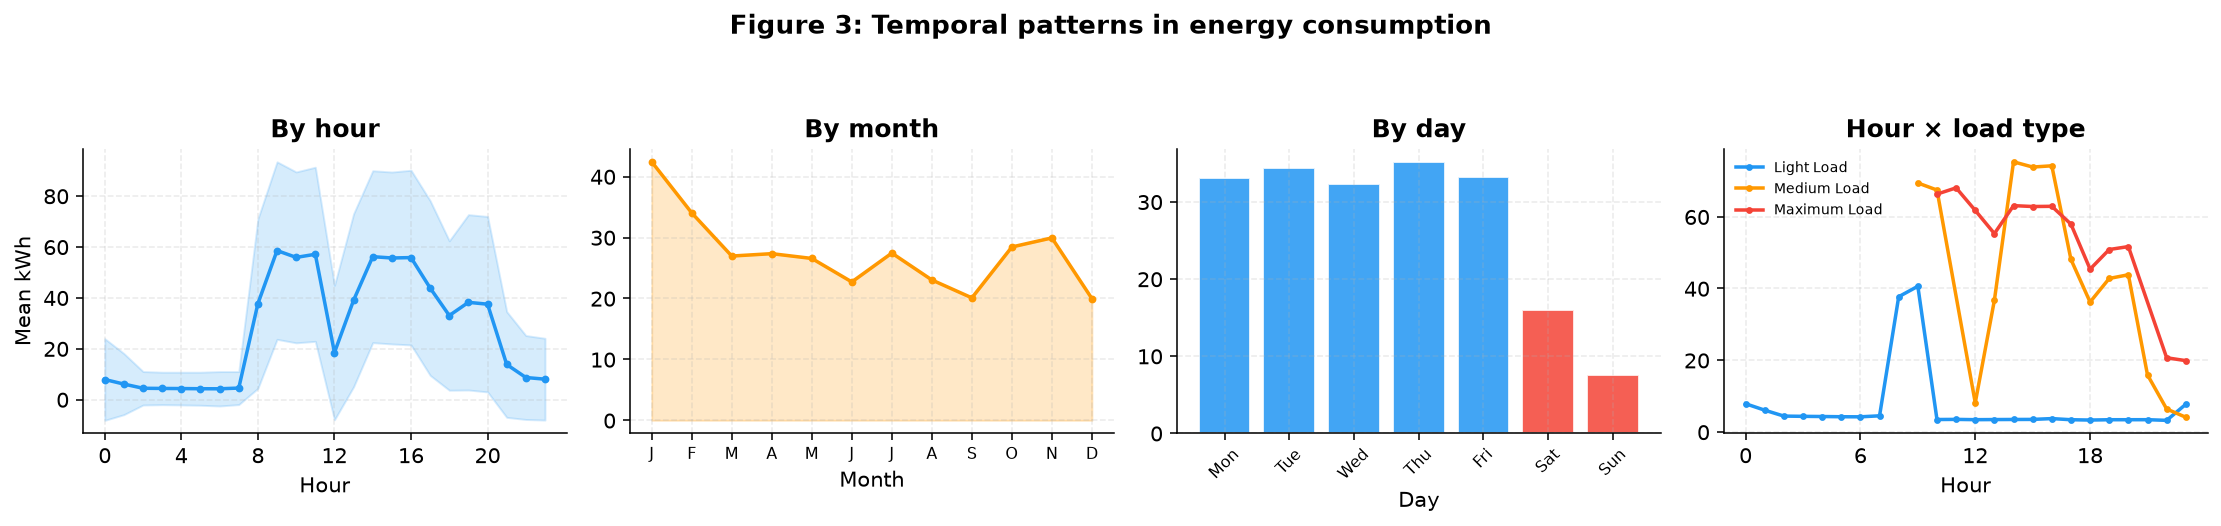

In [10]:
def plot_temporal_patterns(df):
    """Mean usage by hour, month and weekday, and by hour within each load type."""
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
    fig.suptitle("Figure 3: Temporal patterns in energy consumption", fontweight="bold")

    hourly = df.groupby("Hour")[REG_TARGET].agg(["mean", "std"])
    axes[0].plot(hourly.index, hourly["mean"], "o-", color="#2196F3", lw=1.8, ms=3)
    axes[0].fill_between(hourly.index, hourly["mean"] - hourly["std"], hourly["mean"] + hourly["std"],
                         alpha=0.18, color="#2196F3")
    axes[0].set(title="By hour", xlabel="Hour", ylabel="Mean kWh", xticks=range(0, 24, 4))

    monthly = df.groupby("Month")[REG_TARGET].mean()
    axes[1].plot(monthly.index, monthly.values, "o-", color="#FF9800", lw=1.8, ms=3)
    axes[1].fill_between(monthly.index, monthly.values, alpha=0.22, color="#FF9800")
    axes[1].set(title="By month", xlabel="Month", xticks=range(1, 13))
    axes[1].set_xticklabels(list("JFMAMJJASOND"), fontsize=8)

    days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    daily = df.groupby("Day_of_week")[REG_TARGET].mean().reindex(days)
    axes[2].bar(range(7), daily.values, edgecolor="white", alpha=0.85,
                color=["#F44336" if d in ("Saturday", "Sunday") else "#2196F3" for d in days])
    axes[2].set(title="By day", xlabel="Day", xticks=range(7))
    axes[2].set_xticklabels([d[:3] for d in days], rotation=45, fontsize=8)

    for load_type, colour in PALETTE.items():
        by_hour = df[df[CLF_TARGET] == load_type].groupby("Hour")[REG_TARGET].mean()
        axes[3].plot(by_hour.index, by_hour.values, lw=1.8, color=colour, marker="o", ms=2.5,
                     label=load_type.replace("_", " "))
    axes[3].set(title="Hour × load type", xlabel="Hour", xticks=range(0, 24, 6))
    axes[3].legend(fontsize=7)

    fig.tight_layout(rect=[0, 0, 1, 0.92])
    return fig


plot_temporal_patterns(df)
plt.show()

<a id="unsupervised"></a>
## 4. Unsupervised learning: PCA and K-Means

Can the plant's operating structure be recovered from the six modelling features alone, without
ever seeing `Load_Type`?

- **PCA** summarises the features and lets us see whether the load types separate.
- **K-Means** looks for natural groups.

Both are exploratory, so they are fitted on the full dataset. The features are standardised first,
because both methods are sensitive to scale. K-Means runs on the standardised features
themselves; the PCA coordinates are only used to plot the clusters.

### 4.1 Principal component analysis

**Variance:** PC1 and PC2 explain 59.3% of the variance between them, and four components are
needed to pass 80% (87.6%). The features carry several distinct sources of variation rather than
one or two dominant ones.

**What the components mean (from the loadings):**
- **PC1: electrical efficiency and time of day.** `Lead.PF` (+0.60) against `Lag.PF` (−0.55) and
  `Hour` (−0.48), with a smaller `Is_Weekend` term (−0.27).
- **PC2: machinery load and the working week.** `Lag.React.Power` (+0.65) against `Is_Weekend`
  (−0.50), plus `Lag.PF` and `Hour` (both +0.37).
- **PC3: season.** Almost entirely `Month` (+0.98).
- **PC4: weekend versus weekday.** `Is_Weekend` (+0.80) with `Lag.React.Power` (+0.54).

**Load types in PC space:** the PC1–PC2 scatter separates them only partly. Light_Load
concentrates in one region, while Medium_Load and Maximum_Load overlap widely. The classes are
distinguishable but not linearly separable, which foreshadows non-linear classifiers beating
linear ones in Section 6.

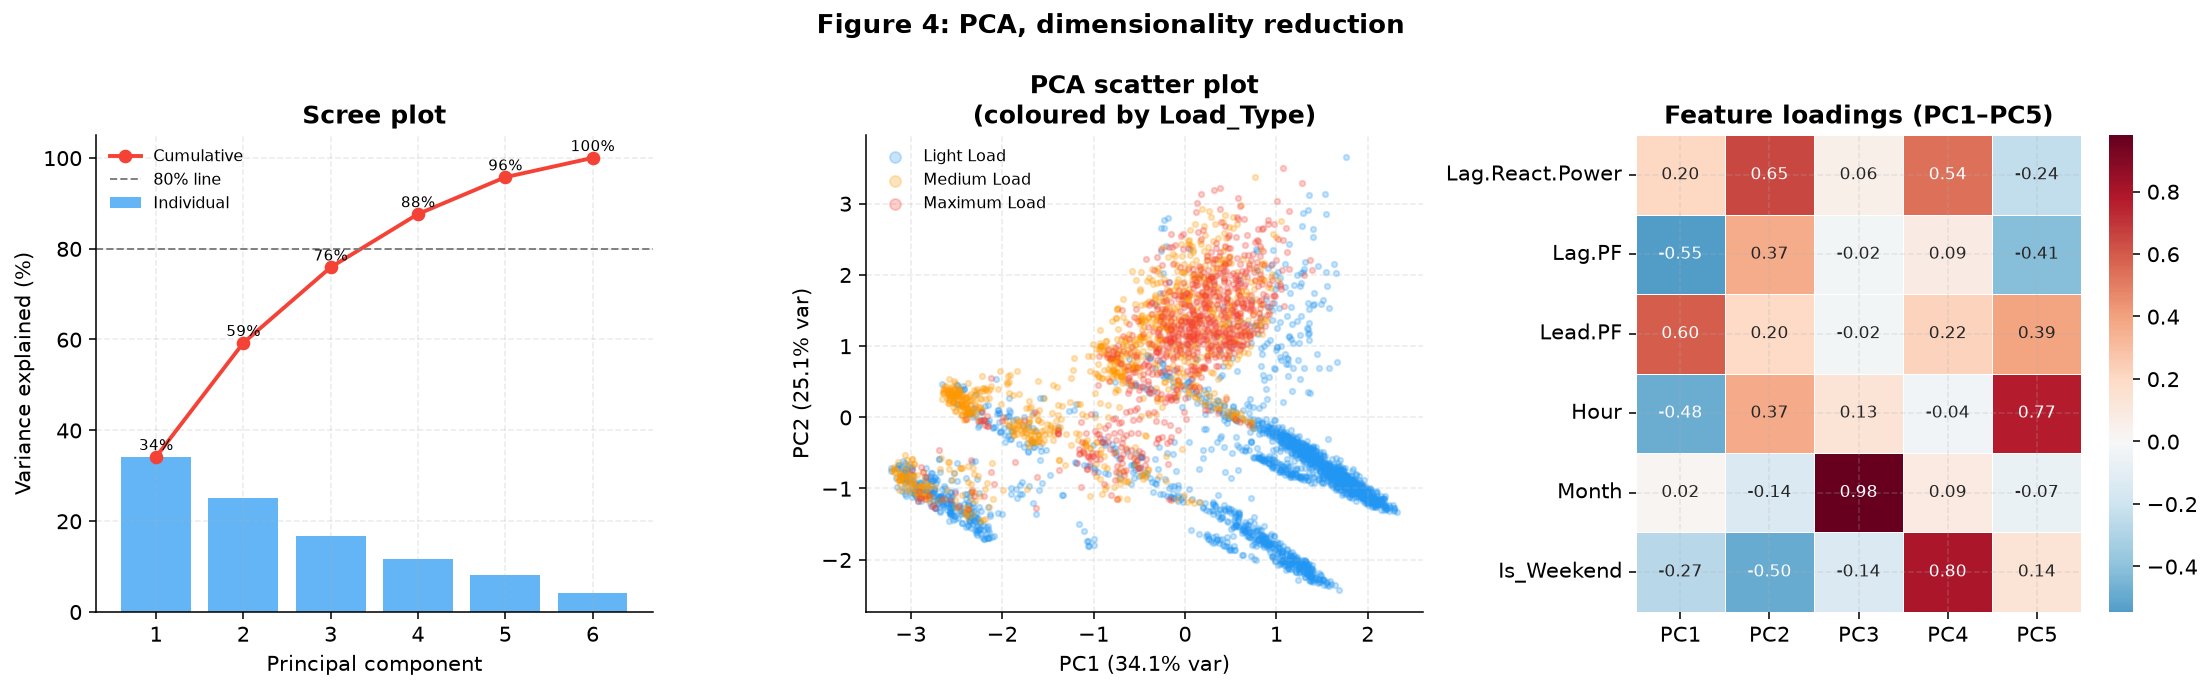

First 1 component: 34.1% of variance
First 2 components: 59.3% of variance
First 3 components: 75.9% of variance
First 4 components: 87.6% of variance
First 5 components: 95.8% of variance
First 6 components: 100.0% of variance

Components needed to pass 80%: 4


In [11]:
def run_pca(X):
    """Standardise X and fit a PCA with one component per feature.

    Returns the standardised data, the fitted PCA, and each row's component scores.
    """
    X_std = StandardScaler().fit_transform(X)
    pca = PCA(n_components=X.shape[1])
    scores = pca.fit_transform(X_std)
    return X_std, pca, scores


def plot_pca(pca, scores, load_type, feature_labels, n_points=4000):
    """Scree plot, a PC1-PC2 scatter coloured by load type, and the loadings heatmap."""
    variance = pca.explained_variance_ratio_
    cumulative = np.cumsum(variance)
    components = range(1, len(variance) + 1)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle("Figure 4: PCA, dimensionality reduction", fontweight="bold")

    axes[0].bar(components, variance * 100, color="#2196F3", alpha=0.7, label="Individual")
    axes[0].plot(components, cumulative * 100, "o-", color="#F44336", lw=2, label="Cumulative")
    axes[0].axhline(80, color="grey", ls="--", lw=1, label="80% line")
    for i, share in enumerate(cumulative, start=1):
        axes[0].annotate(f"{share:.0%}", (i, share * 100 + 1.5), fontsize=7.5, ha="center")
    axes[0].set(title="Scree plot", xlabel="Principal component", ylabel="Variance explained (%)")
    axes[0].legend(fontsize=8)

    # Plot a fixed random sample so the scatter stays readable.
    sample = np.random.RandomState(SEED).choice(len(scores), n_points, replace=False)
    for lt, colour in PALETTE.items():
        in_class = load_type.iloc[sample].to_numpy() == lt
        axes[1].scatter(scores[sample][in_class, 0], scores[sample][in_class, 1],
                        c=colour, alpha=0.25, s=8, label=lt.replace("_", " "))
    axes[1].set(xlabel=f"PC1 ({variance[0]:.1%} var)", ylabel=f"PC2 ({variance[1]:.1%} var)")
    axes[1].set_title("PCA scatter plot\n(coloured by Load_Type)")
    axes[1].legend(fontsize=8, markerscale=2)

    n_shown = min(5, len(variance))
    loadings = pd.DataFrame(pca.components_[:n_shown].T, index=feature_labels,
                            columns=[f"PC{i}" for i in range(1, n_shown + 1)])
    sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[2],
                linewidths=0.5, annot_kws={"size": 8.5})
    axes[2].set_title(f"Feature loadings (PC1–PC{n_shown})")

    fig.tight_layout()
    return fig


X_std, pca, pca_scores = run_pca(df[MODEL_FEATURES])
plot_pca(pca, pca_scores, df[CLF_TARGET], short(MODEL_FEATURES))
plt.show()

cumulative = np.cumsum(pca.explained_variance_ratio_)
for i, share in enumerate(cumulative, start=1):
    print(f"First {i} component{'s' if i > 1 else ''}: {share:.1%} of variance")
print(f"\nComponents needed to pass 80%: {np.argmax(cumulative >= 0.80) + 1}")

### 4.2 K-Means clustering

K is chosen by silhouette score over K = 2 to 8. **K = 4 scores highest (0.3565)**, narrowly
ahead of K = 8 (0.3556). With a near-tie, the smaller and easier-to-interpret solution is
preferred. The elbow plot doesn't settle the choice on its own: its sharpest bend is at K = 3,
and inertia falls only gradually after that.

A silhouette this moderate means the operating states overlap rather than forming cleanly
separated groups. That reflects how the plant actually runs; it isn't a modelling failure.

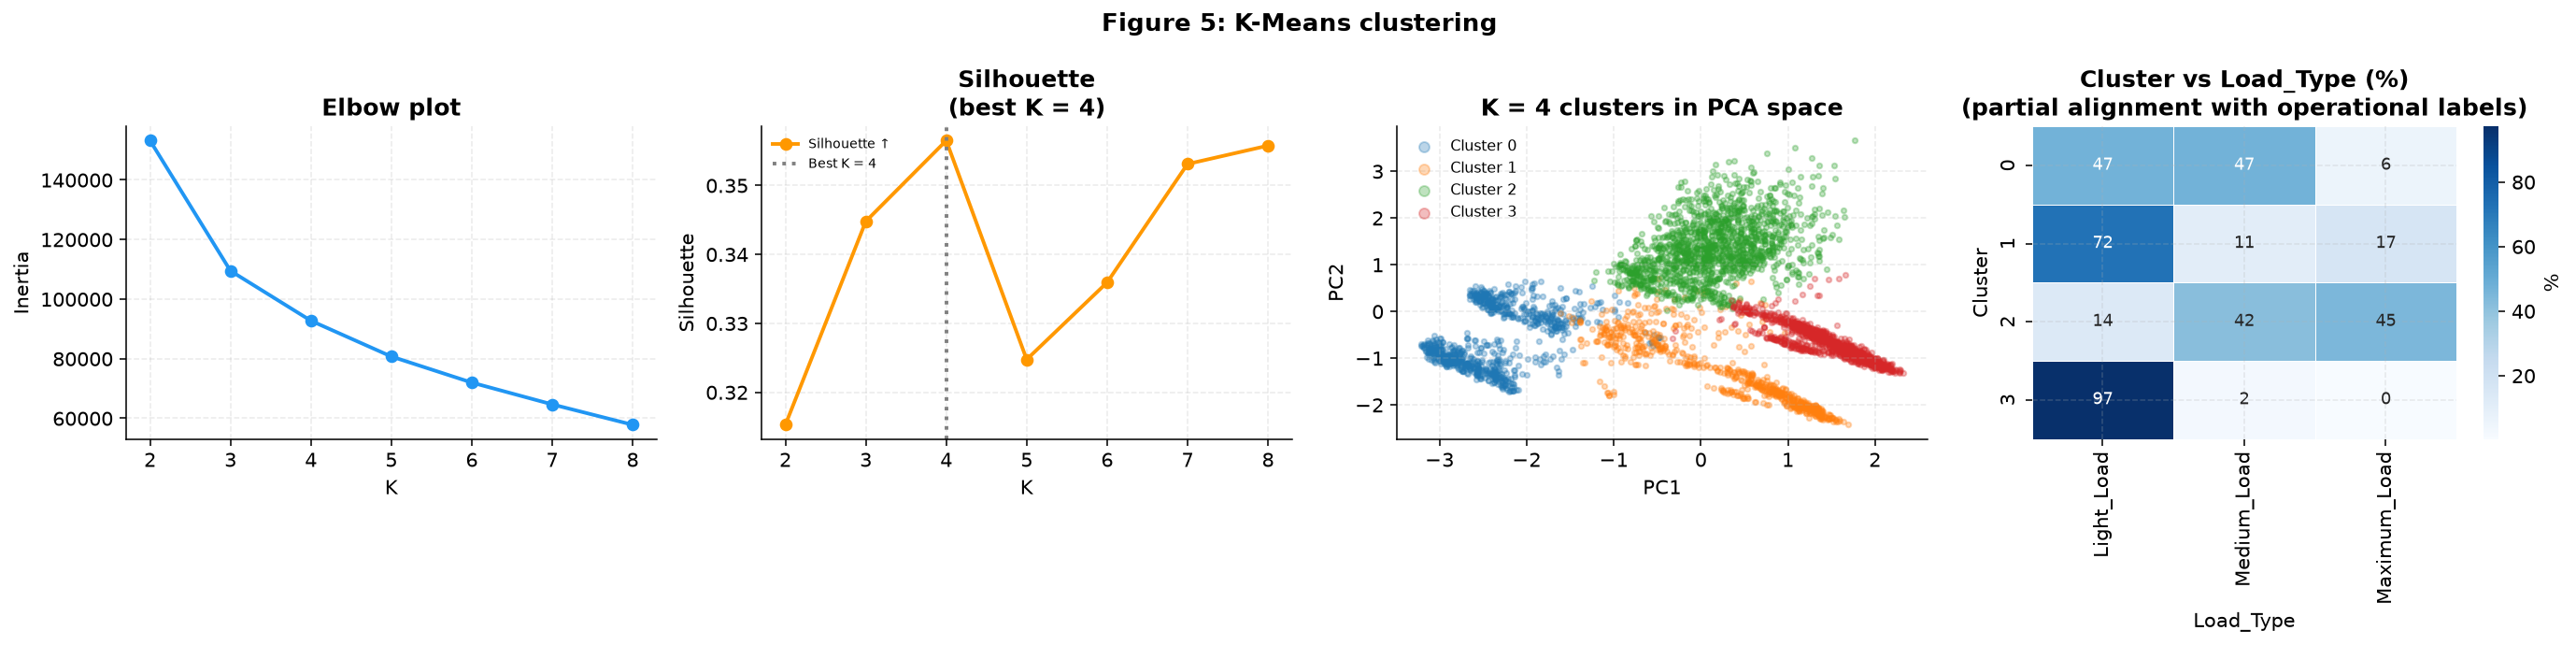

Best K = 4, silhouette = 0.3565


In [12]:
def scan_k(X_std, k_values):
    """Inertia (elbow) and silhouette score for each candidate number of clusters."""
    rows = []
    for k in k_values:
        km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
        labels = km.fit_predict(X_std)
        silhouette = silhouette_score(X_std, labels, sample_size=5000, random_state=SEED)
        rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette})
    return pd.DataFrame(rows).set_index("k")


def plot_kmeans(scan, clusters, scores, load_type, n_points=4000):
    """Elbow, silhouette, clusters in PCA space, and the load-type mix of each cluster."""
    best_k = scan["silhouette"].idxmax()
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    fig.suptitle("Figure 5: K-Means clustering", fontweight="bold")

    axes[0].plot(scan.index, scan["inertia"], "o-", color="#2196F3", lw=2)
    axes[0].set(title="Elbow plot", xlabel="K", ylabel="Inertia")

    axes[1].plot(scan.index, scan["silhouette"], "o-", color="#FF9800", lw=2, label="Silhouette ↑")
    axes[1].axvline(best_k, color="grey", ls=":", lw=2, label=f"Best K = {best_k}")
    axes[1].set(xlabel="K", ylabel="Silhouette")
    axes[1].set_title(f"Silhouette\n(best K = {best_k})")
    axes[1].legend(fontsize=7)

    sample = np.random.RandomState(SEED).choice(len(scores), n_points, replace=False)
    colours = plt.get_cmap("tab10")
    for c in range(best_k):
        in_cluster = clusters[sample] == c
        axes[2].scatter(scores[sample][in_cluster, 0], scores[sample][in_cluster, 1],
                        c=[colours(c)], alpha=0.3, s=8, label=f"Cluster {c}")
    axes[2].set(title=f"K = {best_k} clusters in PCA space", xlabel="PC1", ylabel="PC2")
    axes[2].legend(fontsize=8, markerscale=2)

    mix = pd.crosstab(pd.Series(clusters, name="Cluster"),
                      pd.Series(load_type.to_numpy(), name="Load_Type"), normalize="index")
    mix = mix[LOAD_ORDER] * 100
    sns.heatmap(mix, annot=True, fmt=".0f", cmap="Blues", ax=axes[3], linewidths=0.5,
                annot_kws={"size": 9}, cbar_kws={"label": "%"})
    axes[3].set_title("Cluster vs Load_Type (%)\n(partial alignment with operational labels)")

    fig.tight_layout()
    return fig


scan = scan_k(X_std, range(2, 9))
best_k = scan["silhouette"].idxmax()
clusters = KMeans(n_clusters=best_k, random_state=SEED, n_init=10).fit_predict(X_std)

plot_kmeans(scan, clusters, pca_scores, df[CLF_TARGET])
plt.show()
print(f"Best K = {best_k}, silhouette = {scan['silhouette'].max():.4f}")

In [13]:
def cluster_profiles(df, clusters):
    """Size, consumption, timing and dominant load type of each cluster."""
    grouped = df.assign(Cluster=clusters).groupby("Cluster")
    profile = grouped.agg(
        Count=(REG_TARGET, "count"),
        Mean_kWh=(REG_TARGET, "mean"),
        Std_kWh=(REG_TARGET, "std"),
        Mean_Hour=("Hour", "mean"),
        Pct_Weekend=("Is_Weekend", "mean"),
        Dominant_Label=(CLF_TARGET, lambda s: s.value_counts().index[0]),
        Dominant_Share=(CLF_TARGET, lambda s: s.value_counts(normalize=True).iloc[0]),
    )
    return profile.round(2)


print(cluster_profiles(df, clusters).to_string())

         Count  Mean_kWh  Std_kWh  Mean_Hour  Pct_Weekend Dominant_Label  Dominant_Share
Cluster                                                                                 
0         7237      4.29     1.82      16.39         0.55     Light_Load            0.47
1         5853     15.43    21.62       8.31         1.00     Light_Load            0.72
2        13058     61.49    29.75      14.84         0.01   Maximum_Load            0.45
3         8892      3.97     3.66       4.71         0.00     Light_Load            0.97


**What the four clusters represent**

The clusters combine load intensity, time of day and the working week:

| Cluster | Size | Profile | Reading |
|---|---|---|---|
| 0 | 7,237 | Low use (4.29 kWh), late in the day (mean hour 16.4), 55% weekend | Split almost evenly between Light and Medium Load: a transitional, ambiguous state |
| 1 | 5,853 | Moderate, variable use (15.43 ± 21.62 kWh), mornings (mean hour 8.3), all weekend | Mostly Light_Load, but the higher, more variable use suggests weekend maintenance or testing rather than idling |
| 2 | 13,058 | High use (61.49 kWh), daytime (mean hour 14.8), almost no weekends | The main production regime, mixing Maximum and Medium Load |
| 3 | 8,892 | Lowest use (3.97 kWh), early morning (mean hour 4.7), weekdays only | Weekday idle: 97% Light_Load |

K-Means finds a richer structure than the three `Load_Type` labels. Light_Load splits into
several distinct low-intensity regimes, while daytime production merges Maximum and Medium Load.
The labelled schedule simplifies a more continuous operating reality.

<a id="regression"></a>
## 5. Regression: predicting `Usage_kWh`

**Goal:** predict the electricity used in each 15-minute interval from the six modelling features.

- **Split:** 80% training, 20% test (`random_state = SEED`).
- **Tuning:** grid search with 5-fold cross-validation on the training set only. The grid is chosen
  by **RMSE**; MAE and R² are recorded too.
- **Selection:** the best model is the one with the lowest *cross-validated* RMSE. The test set is
  only used to report final performance.

| Model | Family | Why it's included |
|---|---|---|
| Linear Regression | Linear | Baseline: is the relationship roughly linear? |
| Lasso | Penalised linear | Does L1 regularisation simplify the linear model? |
| Decision Tree | Tree | Interpretable, threshold-like rules |
| Random Forest | Ensemble | Bagged trees for higher accuracy |

Every model sits in a pipeline that standardises its inputs first. Linear models need this; tree
models don't, but one shared setup keeps the comparison simple.

Usage can't be negative, so the results also report predictions **clipped at zero**. Model
comparison uses the raw predictions.

### 5.1 A shared tuning and evaluation helper

Regression and classification follow the same recipe:
1. For each model, grid-search its hyperparameters with cross-validation on the training set.
2. Refit the best settings on the whole training set.
3. Score the result once on the test set.

The helper below implements that recipe once, and both tasks call it. Each task passes in its own
scorers and its own function for test-set metrics.

In [14]:
def tune_and_evaluate(models, X_train, X_test, y_train, y_test, *, cv, scoring, refit, test_metrics):
    """Grid-search each model on the training set, then score its best version on the test set.

    models:       {name: (estimator, param_grid)}. Each estimator runs after a StandardScaler, so
                  grid keys are prefixed with "model__".
    scoring:      {label: sklearn scorer name}, all recorded from cross-validation.
    refit:        the scoring label used to choose the best hyperparameters.
    test_metrics: function(fitted_model, X_test, y_test) -> {metric: value}.

    Returns a results table sorted best-first by the refit CV score, and {name: fitted model}.
    Scores that sklearn reports as negatives (e.g. neg_root_mean_squared_error) are flipped back
    to positive errors in the table.
    """
    rows, fitted = [], {}
    for name, (estimator, grid) in models.items():
        print(f"Tuning {name} ...")
        search = GridSearchCV(
            Pipeline([("scale", StandardScaler()), ("model", estimator)]),
            param_grid=[grid] if grid else [{}],
            scoring=scoring,
            refit=refit,
            cv=cv,
            n_jobs=-1,
        )
        search.fit(X_train, y_train)
        cv_scores = {f"CV_{label}": search.cv_results_[f"mean_test_{label}"][search.best_index_]
                     for label in scoring}
        rows.append({"Model": name, **cv_scores,
                     **test_metrics(search.best_estimator_, X_test, y_test),
                     "Best_Params": search.best_params_})
        fitted[name] = search.best_estimator_

    results = (pd.DataFrame(rows)
               .sort_values(f"CV_{refit}", ascending=False, kind="stable")
               .reset_index(drop=True))
    for label, scorer in scoring.items():
        if scorer.startswith("neg_"):
            results[f"CV_{label}"] = -results[f"CV_{label}"]
    return results, fitted

### 5.2 Tuning the regression models

In [15]:
X_reg = df[MODEL_FEATURES]
y_reg = df[REG_TARGET]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=TEST_SIZE, random_state=SEED
)
print(f"Train: {Xr_train.shape}   Test: {Xr_test.shape}")

REGRESSION_MODELS = {
    "Linear Regression": (LinearRegression(), {}),
    "Lasso": (
        Lasso(max_iter=5000, random_state=SEED),
        {"model__alpha": [0.0001, 0.001, 0.01, 0.1, 1.0]},
    ),
    "Decision Tree": (
        DecisionTreeRegressor(random_state=REGRESSION_TREE_SEED),
        {"model__max_depth": [5, 10, None], "model__min_samples_leaf": [1, 3, 5]},
    ),
    "Random Forest": (
        RandomForestRegressor(random_state=REGRESSION_TREE_SEED, n_jobs=-1),
        {
            "model__n_estimators": [100, 150, 250],
            "model__max_depth": [10, None],
            "model__min_samples_leaf": [1, 3, 5],
            "model__max_features": ["sqrt", 0.7],
        },
    ),
}


def regression_test_metrics(model, X_test, y_test):
    """RMSE, MAE and R² on the test set, for raw predictions and for predictions clipped at zero."""
    raw = model.predict(X_test)
    clipped = np.clip(raw, 0, None)
    return {
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, raw)),
        "Test_MAE": mean_absolute_error(y_test, raw),
        "Test_R2": r2_score(y_test, raw),
        "Test_RMSE_Clipped": np.sqrt(mean_squared_error(y_test, clipped)),
        "Test_MAE_Clipped": mean_absolute_error(y_test, clipped),
        "Test_R2_Clipped": r2_score(y_test, clipped),
    }


reg_results, reg_models = tune_and_evaluate(
    REGRESSION_MODELS, Xr_train, Xr_test, yr_train, yr_test,
    cv=KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED),
    scoring={"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"},
    refit="RMSE",
    test_metrics=regression_test_metrics,
)

Train: (28032, 6)   Test: (7008, 6)
Tuning Linear Regression ...


Tuning Lasso ...


Tuning Decision Tree ...


Tuning Random Forest ...


### 5.3 Results

In [16]:
print(reg_results.drop(columns="Best_Params").round(4).to_string(index=False))
print("\nBest hyperparameters:")
for _, row in reg_results.iterrows():
    print(f"  {row['Model']:<18} {row['Best_Params']}")

            Model  CV_RMSE  CV_MAE  CV_R2  Test_RMSE  Test_MAE  Test_R2  Test_RMSE_Clipped  Test_MAE_Clipped  Test_R2_Clipped
    Random Forest   1.0195  0.4140 0.9991     0.9244    0.3755   0.9992             0.9244            0.3755           0.9992
    Decision Tree   1.4436  0.6469 0.9981     1.2761    0.5982   0.9985             1.2761            0.5982           0.9985
            Lasso   9.8417  6.9674 0.9132     9.8433    6.9002   0.9137             9.4741            6.3187           0.9201
Linear Regression   9.8417  6.9674 0.9132     9.8433    6.9002   0.9137             9.4741            6.3187           0.9201

Best hyperparameters:
  Random Forest      {'model__max_depth': None, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__n_estimators': 250}
  Decision Tree      {'model__max_depth': None, 'model__min_samples_leaf': 3}
  Lasso              {'model__alpha': 0.0001}
  Linear Regression  {}


**Reading the results**

- **Tree-based models are far ahead of the linear ones.**
  - Random Forest has the lowest cross-validated RMSE (1.02 kWh). On the test set it reaches
    RMSE 0.92 kWh, MAE 0.38 kWh and R² 0.999.
  - Decision Tree comes second, with a test RMSE of 1.28 kWh.
  - The linear models leave about ten times more error (test RMSE 9.84 kWh, R² 0.914).
- **Lasso and Linear Regression give identical results.** Cross-validation picks the smallest
  penalty in the grid (α = 0.0001), so Lasso is effectively unregularised.
- **Cross-validated and test errors are close for every model.** The ranking doesn't depend on
  a lucky split.
- **Clipping at zero only helps the linear models.** They sometimes predict negative usage; the
  tree models never do.

*Benchmark:* the original study reports test RMSEs of 1.127 for Random Forest and 0.241 for its best
model, CUBIST. Those come from a different setup, so the comparison is only indicative:
- a 75/25 split
- 10-fold cross-validation
- all predictors, including CO₂ and `Load_Type`, which are excluded here

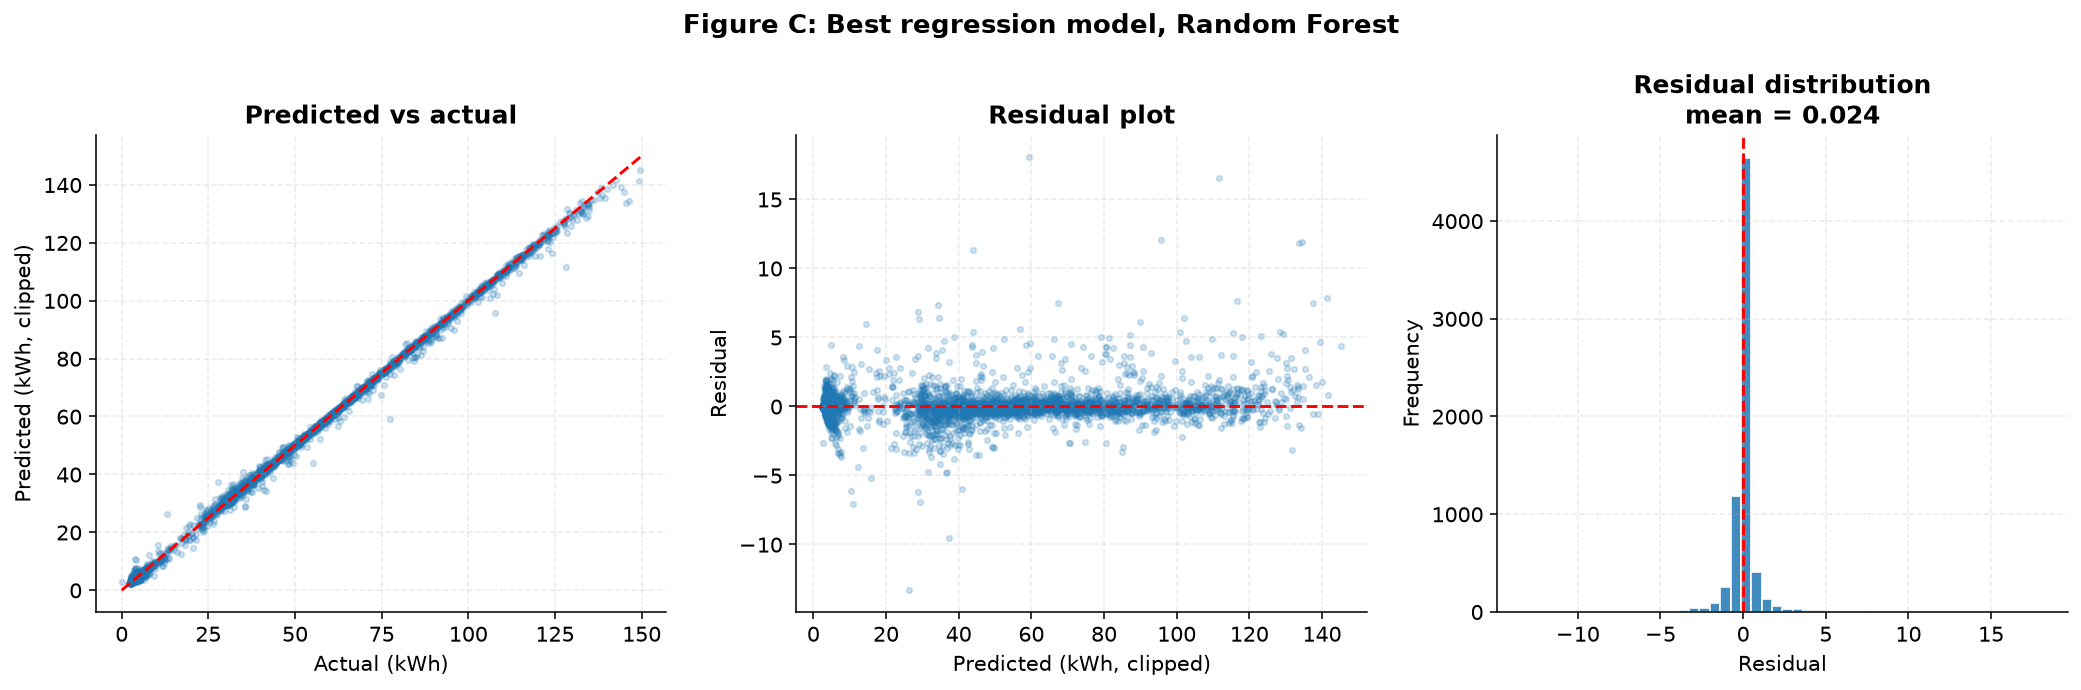

In [17]:
def plot_regression_diagnostics(model_name, y_true, y_pred):
    """Predicted vs actual, residuals vs predicted, and the residual distribution."""
    residuals = y_true - y_pred
    top = max(np.max(y_true), np.max(y_pred))
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"Figure C: Best regression model, {model_name}", fontweight="bold")

    axes[0].scatter(y_true, y_pred, alpha=0.2, s=8)
    axes[0].plot([0, top], [0, top], "r--", lw=1.5)
    axes[0].set(title="Predicted vs actual", xlabel="Actual (kWh)", ylabel="Predicted (kWh, clipped)")

    axes[1].scatter(y_pred, residuals, alpha=0.2, s=8)
    axes[1].axhline(0, color="red", ls="--", lw=1.5)
    axes[1].set(title="Residual plot", xlabel="Predicted (kWh, clipped)", ylabel="Residual")

    axes[2].hist(residuals, bins=50, edgecolor="white", alpha=0.85)
    axes[2].axvline(0, color="red", ls="--", lw=1.5)
    axes[2].set(xlabel="Residual", ylabel="Frequency")
    axes[2].set_title(f"Residual distribution\nmean = {residuals.mean():.3f}")

    fig.tight_layout()
    return fig


best_reg_name = reg_results.loc[0, "Model"]
best_reg_pred = np.clip(reg_models[best_reg_name].predict(Xr_test), 0, None)
plot_regression_diagnostics(best_reg_name, yr_test, best_reg_pred)
plt.show()

The predictions hug the diagonal and the residuals centre on zero with no visible pattern: the
Random Forest is well calibrated across the whole usage range.

### 5.4 What drives energy use?

Two complementary views of feature importance:
- **Random Forest importance:** how much each feature reduces error across the forest's splits.
  It captures non-linear effects.
- **Standardised Lasso coefficients:** the direction and size of each feature's linear effect.

**Both agree that lagging reactive power dominates.** That is the inductive load of running
machinery.
- In the forest, lagging reactive power has importance 0.717, then lagging power factor (0.168)
  and leading power factor (0.081). The three time features share the remaining 3%.
- Lasso ranks the same three features highest (coefficients 23.9, 13.3 and 9.7). Hour adds a
  small positive effect (1.8), Month a small negative one (−1.3), and Is_Weekend almost nothing
  (0.1).

Lasso keeps all six features: none of the coefficients shrinks to zero. Energy use is driven by
how hard the machines are working, not by the clock.

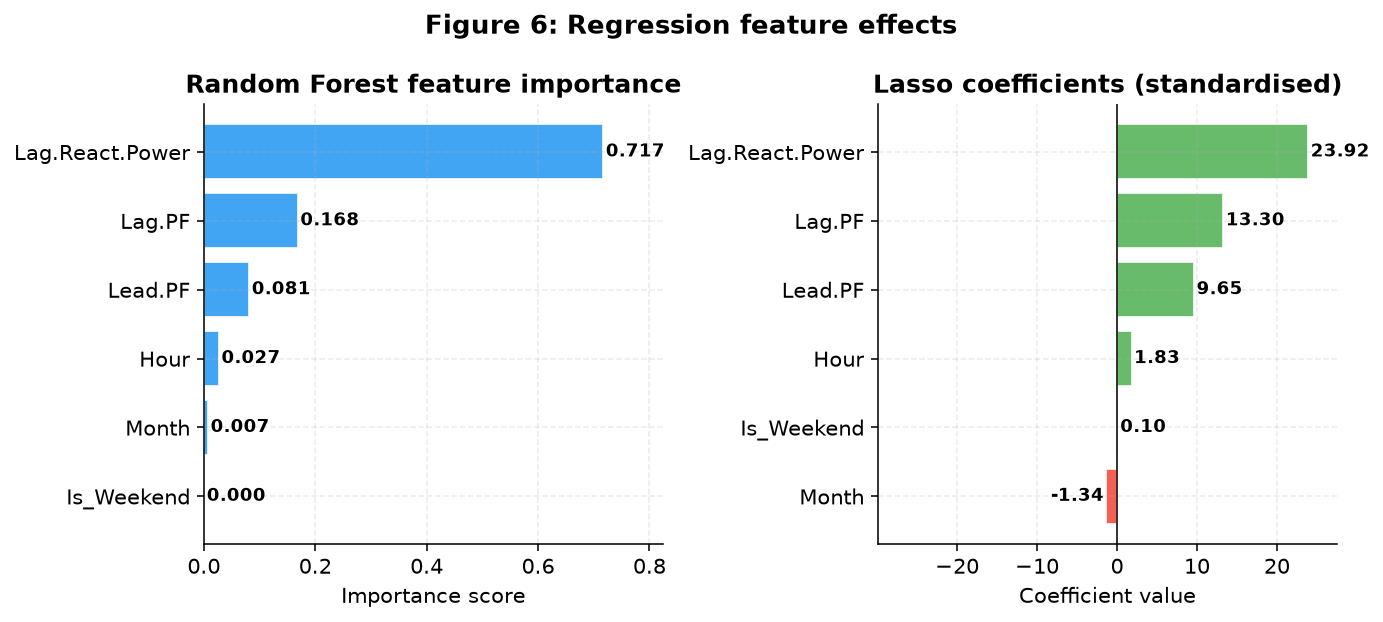

                 RF importance  Lasso coefficient
Lag.React.Power         0.7167            23.9218
Lag.PF                  0.1682            13.3028
Lead.PF                 0.0810             9.6509
Hour                    0.0266             1.8327
Month                   0.0071            -1.3405
Is_Weekend              0.0003             0.1007

Features dropped by Lasso (coefficient = 0): 0


In [18]:
def plot_regression_feature_effects(importance, coefficients):
    """Random Forest importances next to standardised Lasso coefficients."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
    fig.suptitle("Figure 6: Regression feature effects", fontweight="bold")

    importance = importance.sort_values()
    axes[0].barh(importance.index, importance.values, color="#2196F3", alpha=0.85, edgecolor="white")
    for y, value in enumerate(importance.values):
        axes[0].text(value + 0.005, y, f"{value:.3f}", va="center", fontsize=9, fontweight="bold")
    axes[0].set(title="Random Forest feature importance", xlabel="Importance score")
    axes[0].set_xlim(right=importance.max() * 1.15)

    coefficients = coefficients.sort_values()
    colours = ["#4CAF50" if v > 0 else "#F44336" for v in coefficients.values]
    axes[1].barh(coefficients.index, coefficients.values, color=colours, alpha=0.85, edgecolor="white")
    for y, value in enumerate(coefficients.values):
        axes[1].text(value + (0.3 if value >= 0 else -0.3), y, f"{value:.2f}", va="center",
                     ha="left" if value >= 0 else "right", fontsize=9, fontweight="bold")
    axes[1].axvline(0, color="black", lw=0.8)
    axes[1].set(title="Lasso coefficients (standardised)", xlabel="Coefficient value")
    limit = coefficients.abs().max()
    axes[1].set_xlim(-limit * 1.25, limit * 1.15)

    fig.tight_layout()
    return fig


labels = short(MODEL_FEATURES)
rf_importance = pd.Series(reg_models["Random Forest"].named_steps["model"].feature_importances_, index=labels)
lasso_coefs = pd.Series(reg_models["Lasso"].named_steps["model"].coef_, index=labels)

plot_regression_feature_effects(rf_importance, lasso_coefs)
plt.show()

effects = pd.DataFrame({"RF importance": rf_importance, "Lasso coefficient": lasso_coefs})
print(effects.sort_values("RF importance", ascending=False).round(4).to_string())
print(f"\nFeatures dropped by Lasso (coefficient = 0): {(lasso_coefs == 0).sum()}")

<a id="classification"></a>
## 6. Classification: predicting `Load_Type`

**Goal:** identify the plant's operating state (Light, Medium or Maximum Load) from the same six
features. This would support real-time monitoring: an interval whose predicted state disagrees
with the expected schedule could flag a fault or a scheduling error.

- **Split:** 80/20 and **stratified**, so both sets keep the 52/28/21 class mix.
- **Tuning:** grid search with **stratified** 5-fold cross-validation on the training set.
- **Primary metric: macro-F1.** It weights all three classes equally, so a model can't score well
  just by favouring `Light_Load`. Accuracy and multiclass AUC (one-vs-rest, weighted) are
  reported too.
- **Class weights:** `class_weight="balanced"` wherever the model supports it. LDA has no such
  option.

| Model | Family | Why it's included |
|---|---|---|
| Logistic Regression | Linear | Baseline: are the class boundaries roughly linear? |
| LDA | Linear, generative | Assumes Gaussian classes with a shared covariance; its coefficients are easy to interpret |
| Decision Tree | Tree | Interpretable decision rules |
| Random Forest | Ensemble | Bagged trees for higher accuracy |

### 6.1 Tuning the classification models

The same `tune_and_evaluate()` helper from Section 5.1 is reused. Only the models, scorers and
test metrics change.

In [19]:
label_encoder = LabelEncoder()
y_clf = label_encoder.fit_transform(df[CLF_TARGET])  # classes are numbered alphabetically
CLASS_NAMES = list(label_encoder.classes_)
CLASS_SHORT = [name.replace("_Load", "") for name in CLASS_NAMES]

X_clf = df[MODEL_FEATURES]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clf, y_clf, test_size=TEST_SIZE, random_state=SEED, stratify=y_clf
)
train_share = pd.Series(yc_train).value_counts(normalize=True).sort_index()
print(f"Train: {Xc_train.shape}   Test: {Xc_test.shape}")
print("Training class shares:", {CLASS_SHORT[i]: round(s, 3) for i, s in train_share.items()})

CLASSIFICATION_MODELS = {
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED),
        {"model__C": [0.01, 0.1, 1, 10, 50]},
    ),
    "LDA": (LinearDiscriminantAnalysis(), {}),
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
        {"model__max_depth": [5, 10, 15, None], "model__min_samples_leaf": [1, 3, 5]},
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
        {
            "model__n_estimators": [150, 250],
            "model__max_depth": [8, 12, None],
            "model__min_samples_leaf": [1, 3, 5],
            "model__max_features": ["sqrt", 0.7],
        },
    ),
}


def classification_test_metrics(model, X_test, y_test):
    """Macro-F1, weighted F1, accuracy and one-vs-rest weighted AUC on the test set."""
    predicted = model.predict(X_test)
    return {
        "Test_F1_macro": f1_score(y_test, predicted, average="macro"),
        "Test_F1_weighted": f1_score(y_test, predicted, average="weighted"),
        "Test_Accuracy": accuracy_score(y_test, predicted),
        "Test_AUC": roc_auc_score(y_test, model.predict_proba(X_test), multi_class="ovr", average="weighted"),
    }


clf_results, clf_models = tune_and_evaluate(
    CLASSIFICATION_MODELS, Xc_train, Xc_test, yc_train, yc_test,
    cv=StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED),
    scoring={"F1_macro": "f1_macro", "Accuracy": "accuracy", "AUC": "roc_auc_ovr_weighted"},
    refit="F1_macro",
    test_metrics=classification_test_metrics,
)

Train: (28032, 6)   Test: (7008, 6)
Training class shares: {'Light': 0.516, 'Maximum': 0.208, 'Medium': 0.277}
Tuning Logistic Regression ...


Tuning LDA ...
Tuning Decision Tree ...


Tuning Random Forest ...


### 6.2 Results

              Model  CV_F1_macro  CV_Accuracy  CV_AUC  Test_F1_macro  Test_F1_weighted  Test_Accuracy  Test_AUC
      Random Forest       0.9149       0.9215  0.9901         0.9217            0.9284         0.9279    0.9913
      Decision Tree       0.9023       0.9087  0.9798         0.9118            0.9184         0.9177    0.9834
Logistic Regression       0.7034       0.7435  0.9066         0.7081            0.7533         0.7487    0.9093
                LDA       0.6794       0.7253  0.9016         0.6804            0.7315         0.7275    0.9036

Best hyperparameters:
  Random Forest        {'model__max_depth': None, 'model__max_features': 0.7, 'model__min_samples_leaf': 5, 'model__n_estimators': 150}
  Decision Tree        {'model__max_depth': 10, 'model__min_samples_leaf': 1}
  Logistic Regression  {'model__C': 0.01}
  LDA                  {}


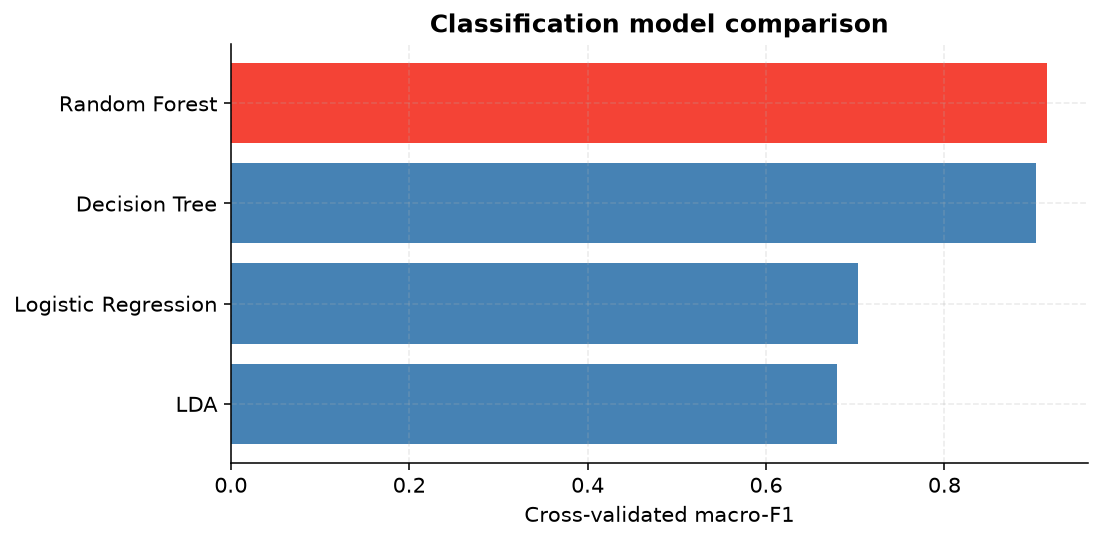

In [20]:
print(clf_results.drop(columns="Best_Params").round(4).to_string(index=False))
print("\nBest hyperparameters:")
for _, row in clf_results.iterrows():
    print(f"  {row['Model']:<20} {row['Best_Params']}")

best_clf_name = clf_results.loc[0, "Model"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(clf_results["Model"], clf_results["CV_F1_macro"],
        color=["#F44336" if m == best_clf_name else "#4682B4" for m in clf_results["Model"]])
ax.invert_yaxis()
ax.set(title="Classification model comparison", xlabel="Cross-validated macro-F1")
fig.tight_layout()
plt.show()

**Reading the results**

- **Tree-based models win clearly.** Random Forest has the highest cross-validated macro-F1
  (0.915). On the test set it reaches macro-F1 0.922, accuracy 0.928 and AUC 0.991. Decision Tree
  is close behind (test macro-F1 0.912).
- **The linear models fall well short:** Logistic Regression reaches 0.708 and LDA 0.680.
  - Their accuracy is higher than their macro-F1, a sign that they handle the common class well
    and the smaller ones poorly.
  - That is exactly the pattern macro-F1 is meant to expose.
- **The class boundaries are non-linear.** The plant doesn't switch state on one variable. Its
  schedule interacts with several electrical and time variables at once, and trees capture that
  with nested rules where linear models can't.
- **Cross-validated and test scores are nearly identical,** so the Random Forest generalises
  rather than fitting one lucky split.

### 6.3 Where the errors are, and what drives the predictions

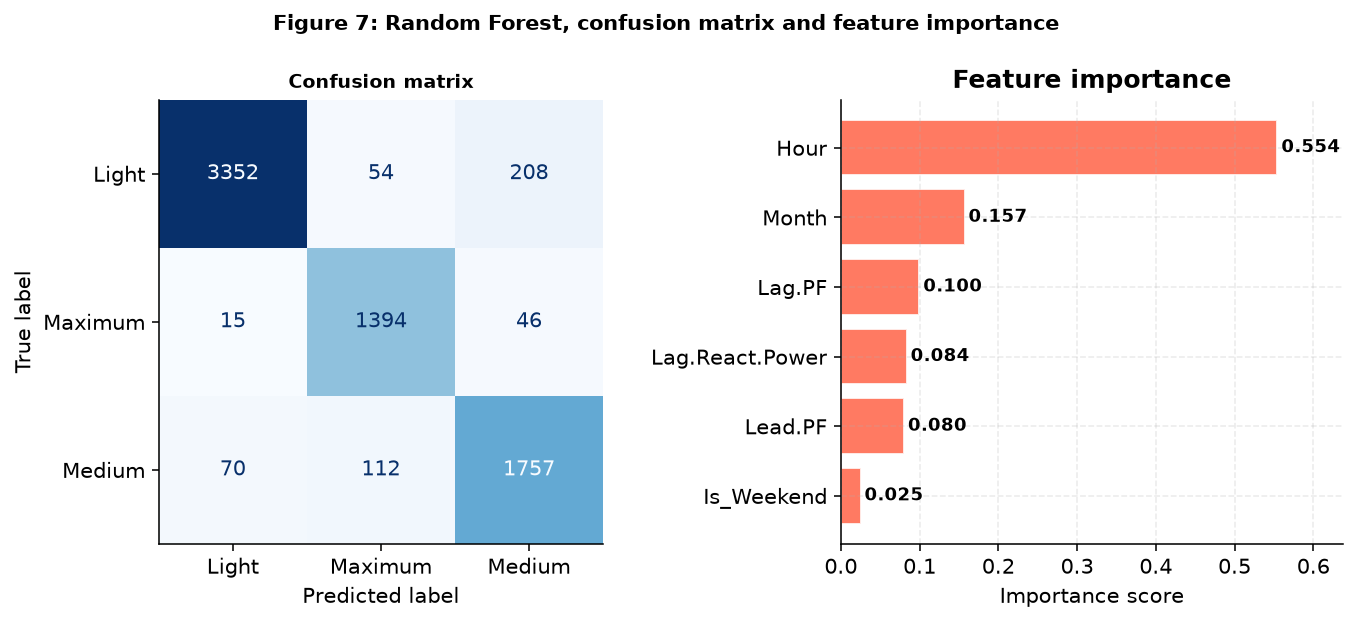

Confusion matrix (rows = actual, columns = predicted):
         Light  Maximum  Medium
Light     3352       54     208
Maximum     15     1394      46
Medium      70      112    1757

              precision    recall  f1-score   support

       Light       0.98      0.93      0.95      3614
     Maximum       0.89      0.96      0.92      1455
      Medium       0.87      0.91      0.89      1939

    accuracy                           0.93      7008
   macro avg       0.91      0.93      0.92      7008
weighted avg       0.93      0.93      0.93      7008

Random Forest importance:
Hour               0.5544
Month              0.1571
Lag.PF             0.0997
Lag.React.Power    0.0836
Lead.PF            0.0802
Is_Weekend         0.0250


In [21]:
def plot_confusion_and_importance(model_name, y_true, y_pred, importance):
    """Test-set confusion matrix next to the model's feature importances."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
    fig.suptitle(f"Figure 7: {model_name}, confusion matrix and feature importance",
                 fontweight="bold", fontsize=11)

    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=CLASS_SHORT).plot(
        cmap="Blues", ax=axes[0], colorbar=False)
    axes[0].set_title("Confusion matrix", fontsize=10)
    axes[0].grid(False)

    importance = importance.sort_values()
    axes[1].barh(importance.index, importance.values, color="tomato", alpha=0.85, edgecolor="white")
    for y, value in enumerate(importance.values):
        axes[1].text(value + 0.005, y, f"{value:.3f}", va="center", fontsize=9, fontweight="bold")
    axes[1].set(title="Feature importance", xlabel="Importance score")
    axes[1].set_xlim(right=importance.max() * 1.15)

    fig.tight_layout()
    return fig


best_clf_pred = clf_models[best_clf_name].predict(Xc_test)
clf_importance = pd.Series(
    clf_models["Random Forest"].named_steps["model"].feature_importances_, index=short(MODEL_FEATURES)
)
plot_confusion_and_importance(best_clf_name, yc_test, best_clf_pred, clf_importance)
plt.show()

print("Confusion matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(confusion_matrix(yc_test, best_clf_pred), index=CLASS_SHORT, columns=CLASS_SHORT).to_string())
print("\n" + classification_report(yc_test, best_clf_pred, target_names=CLASS_SHORT))
print("Random Forest importance:")
print(clf_importance.sort_values(ascending=False).round(4).to_string())

**Errors.** Most test intervals sit on the diagonal of the confusion matrix. Medium_Load is the
hardest class: 1,757 of its 1,939 intervals are classified correctly, and its F1 is 0.89, against
0.95 for Light and 0.92 for Maximum. Most mistakes are between neighbouring states:

| Confused pair | Count |
|---|---|
| Light and Medium | 278 |
| Medium and Maximum | 158 |
| Light and Maximum | 69 |

These are structured, realistic errors. Medium_Load works as a transition between idle and full
production, so it naturally overlaps both of its neighbours.

**Drivers.** `Hour` is by far the most important feature (0.554), followed by `Month` (0.157) and
lagging power factor (0.100). The other electrical variables contribute 0.08 each, and
`Is_Weekend` adds little (0.025) once `Hour` and `Month` are known. The load type depends mainly on the plant's operating schedule,
not on instantaneous electrical readings. That is the opposite of regression, where lagging
reactive power dominated. Section 7 measures how much of the classifier's skill is really
schedule recognition.

### 6.4 How the classes differ: LDA coefficients

LDA's per-class coefficients show the direction in which each standardised feature pushes towards
each class.

In [22]:
lda = clf_models["LDA"].named_steps["model"]
lda_coefficients = pd.DataFrame(lda.coef_, index=CLASS_SHORT, columns=short(MODEL_FEATURES))
print(lda_coefficients.round(3).to_string())

         Lag.React.Power  Lag.PF  Lead.PF   Hour  Month  Is_Weekend
Light             -0.307  -1.259   -0.734 -0.969 -0.113       0.282
Maximum            0.708   1.631    1.242  0.874  0.182      -0.084
Medium             0.040   1.124    0.437  1.150  0.074      -0.463


- **Light:** negative on `Hour`, `Month` and the electrical variables, and positive on
  `Is_Weekend`. It is low-intensity, off-peak operation.
- **Maximum:** strongly positive on all three electrical variables and positive on `Hour`. It is
  daytime, high-demand production.
- **Medium:** the largest positive `Hour` coefficient but weaker electrical terms, and the most
  negative `Is_Weekend`. It is an intermediate weekday state below full production.

<a id="ablation"></a>
## 7. Ablation: how much of `Load_Type` is just the schedule?

The original study (Sathishkumar et al., 2021, Table 2) shows that `Load_Type` follows a fixed
KEPCO tariff schedule by time of day and season. For example, Light_Load covers 23:00–09:00 all
year. With `Hour`, `Month` and `Is_Weekend` among the features, the classifier can partly
*reconstruct that rule* instead of learning from the electrical behaviour. That would explain why
`Hour` dominates the importances.

To measure this, the Random Forest is retrained on the three **electrical features only**. It uses
the same estimator settings, class weights, hyperparameter grid, stratified split and CV folds as
in Section 6; only the features change.

In [23]:
Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    df[ELECTRICAL_FEATURES], y_clf, test_size=TEST_SIZE, random_state=SEED, stratify=y_clf
)
ablation_results, ablation_models = tune_and_evaluate(
    {"Random Forest (electrical only)": CLASSIFICATION_MODELS["Random Forest"]},
    Xe_train, Xe_test, ye_train, ye_test,
    cv=StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED),
    scoring={"F1_macro": "f1_macro", "Accuracy": "accuracy", "AUC": "roc_auc_ovr_weighted"},
    refit="F1_macro",
    test_metrics=classification_test_metrics,
)
electrical_pred = ablation_models["Random Forest (electrical only)"].predict(Xe_test)


def summarise_classifier(y_true, y_pred):
    """Per-class F1, macro-F1 and accuracy in one row."""
    per_class = f1_score(y_true, y_pred, average=None)
    return {**dict(zip(CLASS_SHORT, per_class)),
            "Macro F1": f1_score(y_true, y_pred, average="macro"),
            "Accuracy": accuracy_score(y_true, y_pred)}


comparison = pd.DataFrame({
    "All six features": summarise_classifier(yc_test, best_clf_pred),
    "Electrical only (3)": summarise_classifier(ye_test, electrical_pred),
}).T
print(comparison.round(4).to_string())
drop = comparison.loc["All six features", "Macro F1"] - comparison.loc["Electrical only (3)", "Macro F1"]
print(f"\nDrop in macro-F1 without the time features: {drop:.4f}")
print("Best hyperparameters (electrical only):", ablation_results.loc[0, "Best_Params"])

Tuning Random Forest (electrical only) ...


                      Light  Maximum  Medium  Macro F1  Accuracy
All six features     0.9508   0.9247  0.8896    0.9217    0.9279
Electrical only (3)  0.8628   0.6327  0.4916    0.6624    0.7103

Drop in macro-F1 without the time features: 0.2593
Best hyperparameters (electrical only): {'model__max_depth': 12, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__n_estimators': 250}


**What the ablation shows**

- **Without the time features, macro-F1 falls from 0.92 to 0.66, a drop of 0.26.** About a quarter
  of the full model's score comes from recognising the schedule.
- **The electrical features still carry real signal.** 0.66 is far above the 0.33 expected from
  random guessing across three classes.
- **The loss is uneven across classes.**
  - Light_Load stays easy to recognise from electrical readings alone (F1 0.86).
  - The two daytime states are much harder to tell apart: Maximum falls to 0.63 and Medium to 0.49.

So the full model's performance combines two things working together: recognising the schedule
behind the label, and detecting genuine electrical patterns. It isn't simply leakage.

## Summary

| Task | Best model | Headline result |
|---|---|---|
| Regression: `Usage_kWh` | Random Forest | Test RMSE 0.92 kWh, R² 0.999; lagging reactive power drives usage |
| Classification: `Load_Type` | Random Forest | Test macro-F1 0.92, AUC 0.99; time of day drives the label |
| Unsupervised | K-Means, K = 4 | Four overlapping operating regimes; Light_Load splits into several low-intensity states |

Tree-based models beat linear ones in both supervised tasks, so the relationships are
non-linear. The two tasks depend on different things:
- **Energy use** follows how hard the machines are working.
- **The load-type label** mostly follows the clock.

**Limitations and next steps**
- **One plant, one year.** All 2018 data comes from a single site; results may not transfer to
  other factories or years.
- **Random splits.** Neighbouring 15-minute readings are highly correlated, so a random split is
  optimistic. A time-ordered split would be a stricter test.
- **Midnight timestamps.** Each day's last reading (23:45–24:00) is stamped 00:00 on the same date
  instead of the next day. This notebook keeps the data as published; correcting it would shift
  `Hour` slightly for those rows.